In [4]:
import json

# Load JSON file
with open("experiment_results.json", "r") as f:
    data = json.load(f)

# Extract values
train_acc = data["final_metrics"]["train_acc"]
val_acc   = data["final_metrics"]["val_acc"]
test_acc  = data["final_metrics"]["test_acc"]

precision = data["test_metrics"]["precision_macro"]
recall    = data["test_metrics"]["recall_macro"]
f1        = data["test_metrics"]["f1_macro"]

# Print results
print("===== FINAL ACCURACY =====")
print(f"Train Accuracy: {train_acc:.2f}%")
print(f"Validation Accuracy: {val_acc:.2f}%")
print(f"Test Accuracy: {test_acc:.2f}%")

print("\n===== MACRO METRICS =====")
print(f"Precision (Macro): {precision:.4f}")
print(f"Recall (Macro):    {recall:.4f}")
print(f"F1 Score (Macro):  {f1:.4f}")

===== FINAL ACCURACY =====
Train Accuracy: 91.98%
Validation Accuracy: 92.81%
Test Accuracy: 89.35%

===== MACRO METRICS =====
Precision (Macro): 0.8556
Recall (Macro):    0.8498
F1 Score (Macro):  0.8502


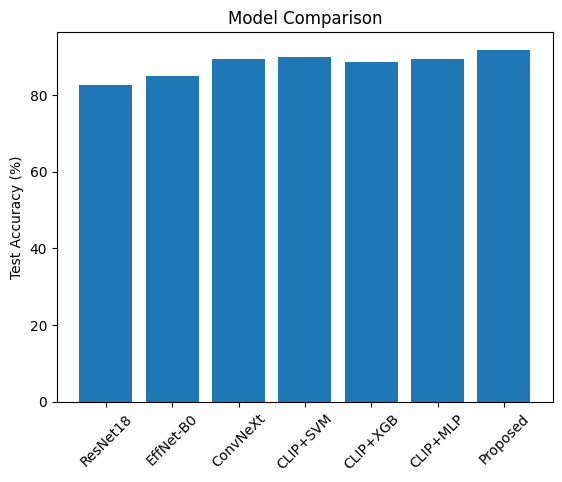

In [5]:
import matplotlib.pyplot as plt

models = [
    "ResNet18",
    "EffNet-B0",
    "ConvNeXt",
    "CLIP+SVM",
    "CLIP+XGB",
    "CLIP+MLP",
    "Proposed"
]

accuracy = [82.62, 84.83, 89.42, 89.86, 88.51, 89.35, 91.80]

plt.figure()
plt.bar(models, accuracy)
plt.xticks(rotation=45)
plt.ylabel("Test Accuracy (%)")
plt.title("Model Comparison")
plt.show()

In [7]:
import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

num_classes = 9  # or set dynamically if you saved it

model = nn.Sequential(
    nn.Linear(512, 256),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256, num_classes)
).to(device)

In [8]:
torch.save(model.state_dict(), "FrozenCLIP_2LayerMLP.pth")

In [9]:
model.load_state_dict(torch.load("FrozenCLIP_2LayerMLP.pth", map_location=device))
model.eval()

C:\Users\Acer\AppData\Local\Temp\ipykernel_21556\4011204161.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("FrozenCLIP_2LayerMLP.pth", 

Sequential(
  (0): Linear(in_features=512, out_features=256, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.3, inplace=False)
  (3): Linear(in_features=256, out_features=9, bias=True)
)

In [11]:
import torch
import numpy as np
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt

model.eval()

y_score = []
y_true = []

with torch.no_grad():
    for X, y in test_loader:
        X = X.to(device)
        outputs = model(X)
        
        probs = torch.softmax(outputs, dim=1)  # IMPORTANT
        
        y_score.append(probs.cpu().numpy())
        y_true.append(y.numpy())

y_score = np.concatenate(y_score)
y_true = np.concatenate(y_true)

NameError: name 'test_loader' is not defined